# Funkcje kwadratowe i układy liniowe

## Funkcje z zajęć

Dokładny GD zapisany przez residuum, kwadrat normy energetycznej i macierz wygładzania.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from time import perf_counter

from cvxopt import matrix, spmatrix, cholmod  # metoda Chol do rzadkich macierzy

In [2]:
def gd(A, b, x0, eps=1e-6, max_iter=20_000,
       keep_history=True, time_limit=np.inf):
    start = perf_counter()
    x = np.array(x0, dtype=float)
    Ax = A @ x0
    r = b - Ax  # residuum w punkcie x
    X = [x.copy()] if keep_history else []
    R = [np.linalg.norm(r)]
    T = [0.]
    status = "limit iteracji"
    for k in range(max_iter):
        if not np.isfinite(R[-1]):
            status = "nieskończone residuum"
            break
        if R[-1] <= eps:
            break
        if perf_counter() - start >= time_limit:
            status = "limit czasu"
            break
        Ar = A @ r
        alpha = (r @ r) / (r @ Ar)  # dokładny krok
        x = x + alpha * r  # nowy punkt
        Ax = Ax + alpha * Ar  # aktualizacja Ax
        r = b - Ax  # residuum w nowym punkcie
        if keep_history:
            X.append(x.copy())
        R.append(np.linalg.norm(r))
        T.append(perf_counter() - start)
    if R[-1] <= eps:
        status = "OK"
    return {"x": x, "X": np.array(X), "R": np.array(R),
            "T": np.array(T), "status": status}

In [3]:
def energy(A, x, x_star):
    e = x - x_star
    return e @ (A @ e)


def positive(values):
    values = np.asarray(values)
    return np.where(values > 0, values, np.nan) 

assert np.isclose(energy(np.diag([1., 10.]), np.ones(2), np.zeros(2)), 11.)

In [4]:
def volume_problem(m, rho=1.):
    rng = np.random.default_rng(2026)
    n = m**3
    grid = np.arange(n).reshape(m, m, m)
    i = np.concatenate([grid[:-1].ravel(), grid[:, :-1].ravel(),
                        grid[:, :, :-1].ravel()])
    j = np.concatenate([grid[1:].ravel(), grid[:, 1:].ravel(),
                        grid[:, :, 1:].ravel()])
    weights = rng.uniform(0.5, 1.5, size=len(i))
    W = sparse.coo_matrix((weights, (i, j)), shape=(n, n)).tocsr()
    W = W + W.T
    degree = np.asarray(W.sum(axis=1)).ravel()
    D = sparse.diags(degree, format="csr")
    I = sparse.eye(n, format="csr")
    L_w = D - W  # macierz członu wygładzającego
    A = I + rho * L_w  # macierz układu z warunku optymalności

    q = np.linspace(-1., 1., m)
    radius2 = q[:, None, None]**2 + q[None, :, None]**2 + q[None, None, :]**2
    signal = (radius2 < 0.55**2).astype(float)
    y = signal.ravel() + rng.normal(scale=0.3, size=n)
    return {"A": A, "y": y, "signal": signal}

## 1. Residuum a błąd rozwiązania

Dla symetrycznej dodatnio określonej macierzy $A$, $b\neq0$ i $Ax^\star=b$ wyprowadź nierówność
$$\|x-x^\star\|_2\leq\frac{\|b-Ax\|_2}{\lambda_{\text{min}}(A)}.$$
Następnie zbadaj **jeden krok** dokładnego GD dla
$$A=\operatorname{diag}(10^{-4},1),\qquad x^\star=(1,1),\qquad b=Ax^\star,\qquad x_0=0.$$
Porównaj normę residuum i normę błędu rozwiązania po tym kroku. Czy kryterium stopu z tolerancją
$10^{-3}$ zakończyłoby obliczenia? Jak dokładny byłby wynik i dlaczego nie przeczy to nierówności?

# Rozwiązanie

Niech $e=x-x^\star$ i $r=b-Ax$.
$$r=Ax^\star-Ax=-Ae\qquad\Longrightarrow\qquad e=-A^{-1}r$$
($A>0$, więc jest odwracalna). Z rozkładu spektralnego $A=V\Lambda V^\top$ ($V$ ortogonalna, $\lambda_i>0$), zapisując $e=\sum_i c_iv_i$:
$$\|r\|_2^2=\|Ae\|_2^2=\sum_i\lambda_i^2c_i^2\;\geq\;\lambda_{\min}^2\sum_ic_i^2=\lambda_{\min}^2\|e\|_2^2 .$$
Po spierwiastkowaniu i podzieleniu przez $\lambda_{\min}>0$:
$$\|x-x^\star\|_2\leq\frac{\|b-Ax\|_2}{\lambda_{\min}(A)}.$$
Równość zachodzi, gdy błąd $e$ jest wektorem własnym dla $\lambda_{\min}$.

In [5]:
A = np.diag([1e-4, 1.])
x_star = np.array([1., 1.])
b = A @ x_star
x0 = np.zeros(2)
lam_min = np.linalg.eigvalsh(A)[0]

# tolerancja 1e-3, limit 20 000 iteracji
result = gd(A, b, x0, eps=1e-3, max_iter=20_000)
assert len(result["R"]) - 1 == 1  # stop po jednym kroku

r0 = b - A @ x0
alpha0 = (r0 @ r0) / (r0 @ (A @ r0))
x1 = result["x"]
r1 = b - A @ x1
e1 = x1 - x_star

print(f"α₀ = {alpha0:.10f}")
print(f"x₁ = ({x1[0]:.6e}, {x1[1]:.10f})")
print(f"r₁ = ({r1[0]:.4e}, {r1[1]:.4e})      x₁ − x* = ({e1[0]:.6f}, {e1[1]:.4e})")
print(f"kroki: {len(result['R']) - 1} | końcowe ‖r‖ = {result['R'][-1]:.4e} | status: {result['status']}")
print(f"‖x₁ − x*‖ = {np.linalg.norm(e1):.6f}  (względny błąd {np.linalg.norm(e1) / np.linalg.norm(x_star):.1%})")
print(f"oszacowanie ‖r₁‖ / λ_min = {np.linalg.norm(r1) / lam_min:.6f}")

α₀ = 1.0000000100
x₁ = (1.000000e-04, 1.0000000100)
r₁ = (9.9990e-05, -9.9990e-09)      x₁ − x* = (-0.999900, 9.9990e-09)
kroki: 1 | końcowe ‖r‖ = 9.9990e-05 | status: OK
‖x₁ − x*‖ = 0.999900  (względny błąd 70.7%)
oszacowanie ‖r₁‖ / λ_min = 0.999900


Dla porównania ta sama metoda z ostrzejszą tolerancją $10^{-10}$ (pozostałe dane bez zmian):

 k | ‖r_k‖      | ‖x_k − x*‖ | ‖r_k‖/λ_min
 0 | 1.000e+00  | 1.414e+00  | 1.000e+04
 1 | 9.999e-05  | 9.999e-01  | 9.999e-01
 2 | 9.997e-05  | 1.414e-04  | 9.997e-01
 3 | 9.996e-09  | 9.996e-05  | 9.996e-05
 4 | 9.994e-09  | 1.413e-08  | 9.994e-05
 5 | 9.994e-13  | 9.994e-09  | 9.994e-09
kroki: 5 | końcowe ‖r‖ = 9.99e-13 | status: OK


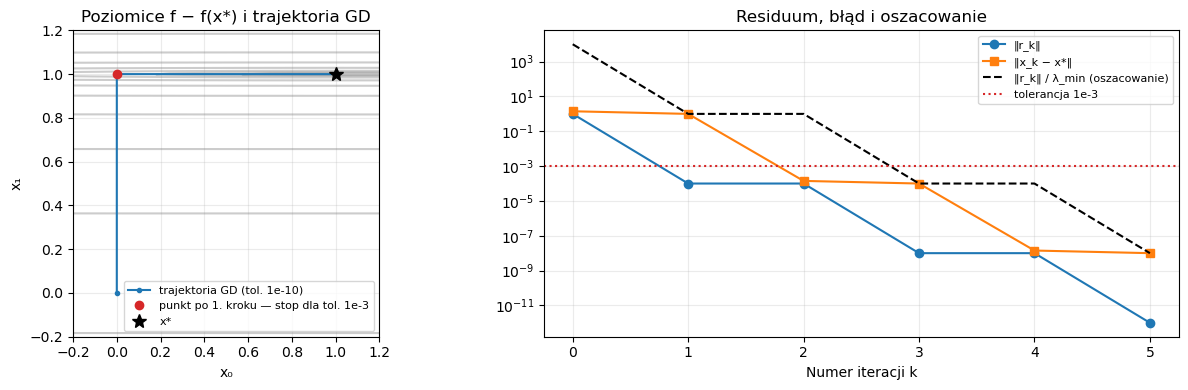

In [6]:
tight = gd(A, b, x0, eps=1e-10, max_iter=20_000)
errors = np.linalg.norm(tight["X"] - x_star, axis=1)
print(" k | ‖r_k‖      | ‖x_k − x*‖ | ‖r_k‖/λ_min")
for k in range(len(errors)):
    print(f"{k:2d} | {tight['R'][k]:.3e}  | {errors[k]:.3e}  | {tight['R'][k] / lam_min:.3e}")
print(f"kroki: {len(tight['R']) - 1} | końcowe ‖r‖ = {tight['R'][-1]:.2e} | status: {tight['status']}")

plot = plt.subplots(1, 2, figsize=(13, 4))
fig = plot[0]
ax_path, ax_err = plot[1]
grid = np.meshgrid(np.linspace(-0.2, 1.2, 300), np.linspace(-0.2, 1.2, 300))
u = grid[0]
v = grid[1]
ax_path.contour(u, v, (1e-4 * (u - 1)**2 + (v - 1)**2) / 2,
                levels=np.geomspace(1e-5, 0.7, 10), colors="grey", alpha=0.4)
ax_path.plot(tight["X"][:, 0], tight["X"][:, 1], ".-", color="C0", label="trajektoria GD (tol. 1e-10)")
ax_path.plot(x1[0], x1[1], "o", color="C3", label="punkt po 1. kroku — stop dla tol. 1e-3")
ax_path.plot(1, 1, "k*", markersize=10, label="x*")
ax_path.set(xlabel="x₀", ylabel="x₁", title="Poziomice f − f(x*) i trajektoria GD")
ax_path.set_aspect("equal")

k = np.arange(len(errors))
ax_err.semilogy(k, tight["R"], "o-", label="‖r_k‖")
ax_err.semilogy(k, errors, "s-", label="‖x_k − x*‖")
ax_err.semilogy(k, tight["R"] / lam_min, "k--", label="‖r_k‖ / λ_min (oszacowanie)")
ax_err.axhline(1e-3, color="C3", linestyle=":", label="tolerancja 1e-3")
ax_err.set(xlabel="Numer iteracji k", title="Residuum, błąd i oszacowanie")
ax_err.set_xticks(k)
for ax in (ax_path, ax_err):
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

**Wnioski:**
- Jeden krok: $\alpha_0=1{,}00000001$, $x_1\approx(10^{-4},\,1{,}00000001)$. Norma residuum $\|r_1\|_2=9{,}999\cdot10^{-5}\le10^{-3}$, więc kryterium stopu kończy obliczenia już po 1 iteracji ze statusem OK.
- Błąd jest jednak ogromny: $\|x_1-x^\star\|_2=0{,}9999$ - pierwsza współrzędna wynosi $10^{-4}$ zamiast $1$. Residuum jest 10 000 razy mniejsze od błędu.
- Powód: $r_0=b=(10^{-4},1)$, więc kierunek spadku to prawie wyłącznie oś $x_1$ (krzywizna 1) i dokładny krok rozwiązuje tylko tę część. Wzdłuż $x_0$ funkcja jest prawie płaska (krzywizna $10^{-4}$), a z $r=-Ae$ błąd $e_0$ daje w residuum tylko $10^{-4}e_0$.
- Nie przeczy to nierówności: $\|x_1-x^\star\|_2\le\|r_1\|_2/\lambda_{\min}=9{,}999\cdot10^{-5}/10^{-4}=0{,}9999$ - zachodzi praktycznie z równością, bo $e_1\approx(-0{,}9999,\,10^{-8})$ jest prawie wektorem własnym dla $\lambda_{\min}$. Nierówność gwarantuje mały błąd dopiero, gdy $\|r\|_2\ll\lambda_{\min}$.
- Z tolerancją $10^{-10}$ GD robi 5 kroków (końcowe $\|r\|_2=9{,}99\cdot10^{-13}$, OK). Dla $k=2$ residuum jest prawie takie jak dla $k=1$ ($\approx10^{-4}$), a błąd spadł z $1$ do $1{,}4\cdot10^{-4}$: sama norma residuum nie mówi, w którym kierunku leży błąd, więc oszacowanie bywa dokładne ($k=1,3,5$) albo zawyżone o kilka rzędów ($k=2,4$).

## 2. To samo uwarunkowanie, różne widma

Przyjmij $n=100$. Porównaj dwie macierze $A_i=Q\Lambda_iQ^\top$ o $\kappa=100$:

- wartości własne $A_1$ są równomiernie rozmieszczone od $1$ do $100$;
- widmo $A_2$ wynosi $1,10,\ldots,10,100$.

Użyj wspólnej ortonormalnej bazy $Q$; możesz przyjąć $Q=I$. Dla obu problemów wybierz
$x^\star=Q\mathbf1$, $x_0=0$, a prawe strony wyznacz osobno jako $b_i=A_ix^\star$.
Stosuj tolerancję $10^{-6}$ i limit 20 000 iteracji.

Porównaj na wykresie $\|x_k-x^\star\|_{A_i}^2/\|x_0-x^\star\|_{A_i}^2$
z oszacowaniem z góry $(99/101)^{2k}$. Czy wspólne uwarunkowanie oznacza identyczne przebiegi?
Porównaj początkowy spadek błędu i późniejsze nachylenie krzywych w skali logarytmicznej. Czy skupienie wartości własnych przyspieszyło GD w tym eksperymencie? Dlaczego w porównaniu używamy wspólnego $Q$ i tego samego $x^\star$? Nie zakładaj z góry, który przykład będzie szybszy.
Zachowaj dane i wyniki do późniejszego porównania z gradientami sprzężonymi.

Przyjmujemy $Q=I$, więc $A_i=\Lambda_i=\operatorname{diag}(\lambda)$ i $x^\star=\mathbf1$.

In [15]:
n = 100
spectra = {
    "A1": np.linspace(1., 100., n),                                # równomiernie 1, 2, ..., 100
    "A2": np.concatenate([[1.], np.full(n - 2, 10.), [100.]]),     # 1, 10, ..., 10, 100
}
labels = {"A1": "A₁: równomierne 1…100", "A2": "A₂: 1, 10, …, 10, 100"}

x_star = np.ones(n)  # Q = I, więc x* = Q·1 = 1
x0 = np.zeros(n)
q = 99 / 101  # (κ − 1)/(κ + 1) dla κ = 100

zad2 = {}
print("macierz                | κ(A)  | kroki | końcowe ‖r‖ | status | E₁/E₀  | E₁₀/E₀  | spadek E / krok (2. połowa)")
for key in spectra:
    values = spectra[key]
    A = np.diag(values)  # Q = I
    b = A @ x_star
    result = gd(A, b, x0, eps=1e-6, max_iter=20_000)
    E = np.array([energy(A, x, x_star) for x in result["X"]])
    ratio = E / E[0]
    k_end = len(ratio) - 1
    late = np.arange(k_end // 2, k_end + 1)
    slope = np.polyfit(late, np.log10(ratio[late]), 1)[0]
    zad2[key] = {"values": values, "A": A, "b": b, "ratio": ratio,
                 "factor": 10**slope, **result}
    print(f"{labels[key]:22s} | {np.linalg.cond(A):5.1f} | {k_end:5d} | {result['R'][-1]:11.2e} | "
          f"{result['status']:6s} | {ratio[1]:.4f} | {ratio[10]:.2e} | ×{10**slope:.5f}")
print(f"oszacowanie z góry: q² = (99/101)² = {q**2:.5f} na krok")

# dane i wyniki zostają w słowniku zad2 oraz w pliku (do porównania z gradientami sprzężonymi)
np.savez_compressed("pd2_zad2.npz", x_star=x_star, x0=x0,
                    **{f"{key}_{name}": zad2[key][name] for key in zad2
                       for name in ["values", "A", "b", "X", "R", "ratio"]})

macierz                | κ(A)  | kroki | końcowe ‖r‖ | status | E₁/E₀  | E₁₀/E₀  | spadek E / krok (2. połowa)
A₁: równomierne 1…100  | 100.0 |   705 |    9.79e-07 | OK     | 0.1111 | 1.45e-03 | ×0.96056
A₂: 1, 10, …, 10, 100  | 100.0 |   711 |    9.78e-07 | OK     | 0.6697 | 1.87e-02 | ×0.96079
oszacowanie z góry: q² = (99/101)² = 0.96079 na krok


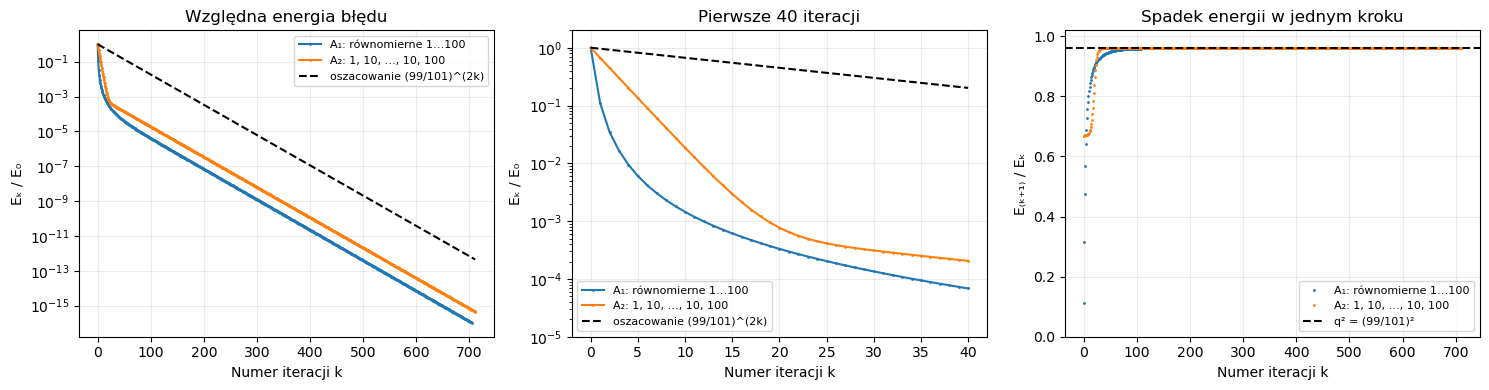

In [8]:
plot = plt.subplots(1, 3, figsize=(15, 4))
fig = plot[0]
ax_full, ax_zoom, ax_rate = plot[1]
longest = max(len(zad2[key]["ratio"]) for key in zad2)
k = np.arange(longest)
for ax, k_max in [(ax_full, longest), (ax_zoom, 41)]:
    for key in zad2:
        ratio = zad2[key]["ratio"][:k_max]
        ax.semilogy(positive(ratio), ".-", markersize=2, label=labels[key])
    ax.semilogy(q**(2 * k[:k_max]), "k--", label="oszacowanie (99/101)^(2k)")
    ax.set(xlabel="Numer iteracji k", ylabel="Eₖ / E₀")
ax_full.set(title="Względna energia błędu")
ax_zoom.set(title="Pierwsze 40 iteracji", ylim=(1e-5, 2))

for key in zad2:
    ratio = zad2[key]["ratio"]
    ax_rate.plot(ratio[1:] / ratio[:-1], ".", markersize=2, label=labels[key])
ax_rate.axhline(q**2, color="k", linestyle="--", label="q² = (99/101)²")
ax_rate.set(xlabel="Numer iteracji k", ylabel="E₍ₖ₊₁₎ / Eₖ",
            title="Spadek energii w jednym kroku", ylim=(0, 1.02))
for ax in (ax_full, ax_zoom, ax_rate):
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

**Wnioski:**
- Oba przebiegi zakończyły się statusem OK (końcowe $\|r\|_2\approx9{,}8\cdot10^{-7}$): 705 iteracji dla $A_1$ i 711 dla $A_2$. Obie krzywe leżą pod oszacowaniem $(99/101)^{2k}$.
- To samo $\kappa$ nie daje identycznych przebiegów. Na początku $A_1$ spada dużo szybciej: po 1 kroku zostaje 11% błędu, a dla $A_2$ aż 67% :DDD. Dokładny krok jest jeden dla wszystkich wartości własnych i dla $A_2$ dopasowuje się głównie do $\lambda=100$, więc 98 składowych z $\lambda=10$ maleje wolno :D
- Później obie krzywe są równoległe i spadają ok. $\times0{,}9608$ na krok, czyli tak jak w oszacowaniu ($q^2=0{,}96079$). Pod koniec błąd zostaje tylko w kierunkach $\lambda=1$ i $\lambda=100$, które obie macierze mają wspólne - tempo zależy wtedy tylko od $\kappa$.
- Skupienie wartości własnych nie przyspieszyło GD ($A_2$: 711 iteracji wobec 705). GD ma jedną długość kroku na raz, więc nie wykorzystuje tego, że $A_2$ ma tylko 3 różne wartości własne (to wykorzystają dopiero gradienty sprzężone).
- Wspólne $Q$ i ten sam $x^\star$ sprawiają, że obie macierze startują z takim samym błędem w każdym kierunku własnym, więc różnice wynikają tylko z widma, a nie z punktu startowego.

## 3. Jedna macierz, wiele obrazów

Na siatce $64^3$ w obszarze $[-1,1]^3$ wykorzystaj wygładzanie z sekcji 5 z $\rho=1$. Macierz $A=I+\rho L_w$ wygeneruj **raz**, zachowując jej wagi przez cały eksperyment.

Przygotuj 20 obrazów. Dla każdego niezależnie wylosuj jednostajnie środek $c\in[-1,1]^3$ oraz promienie $r_1\in(0.1,0.2)$ i $r_2\in(0.3,0.5)$. Ustaw wartość 1 tam, gdzie $r_1<\|p-c\|_2<r_2$, a poza tym 0. Dodaj niezależny szum $N(0,0.3^2)$. Generator z ustalonym ziarnem utwórz raz przed pętlą.

Dla tych samych danych rozwiązuj kolejno $Ax^{(j)}=y^{(j)}$, porównując:

- **Cholesky’ego:** jeden rozkład, wykorzystywany dla wszystkich obrazów;
- **GD ze startu $x_0=0$;**
- **GD ze startu $x_0=y^{(j)}$.**

W obu GD użyj tolerancji bezwzględnej `eps_large`, limitu 20 000 iteracji, `keep_history=False` i `time_limit=np.inf`.

Narysuj trzy krzywe **łącznego czasu przetworzenia pierwszych $k$ obrazów**, $k=1,\ldots,20$. Do czasu Cholesky’ego dolicz jednorazowy koszt przygotowania rozkładu. Generowanie danych i wykresy pomiń w pomiarze; krótkie pomiary powtarzaj.

Dla każdego startu GD ustal, od ilu obrazów Cholesky staje się szybszy; jeśli nie nastąpi to w badanym zakresie, odnotuj ten fakt. Wyjaśnij różnicę między kosztem przygotowania rozkładu a kosztem rozwiązania układu dla kolejnego obrazu. Dla każdego wariantu podaj największą końcową normę residuum spośród 20 obrazów; dla obu startów GD podaj też liczbę przebiegów, które osiągnęły tolerancję.

Dla dwóch wybranych obrazów pokaż przekroje sygnału bez szumu, danych i wyników w warstwie najbliższej środkowi powłoki. Dla danego obrazu zachowaj wspólną warstwę i skalę kolorów.

Ustalenia pomiaru: `eps_large = 1e-12`; konwersja macierzy do formatu CHOLMOD jest poza pomiarem, a koszt przygotowania rozkładu to rozkład symboliczny + numeryczny. Rozkład i każdy przebieg GD mierzymy 3 razy (bierzemy medianę czasu), a krótkie rozwiązanie z gotowym rozkładem - 5 razy (mediana). Dla wszystkich wariantów liczymy też na nowo $\|y-Ax\|_2$, bo GD w kryterium stopu używa residuum aktualizowanego przez $Ax\leftarrow Ax+\alpha Ar$.

In [9]:
eps_large = 1e-12
m = 64
rho = 1.
n_images = 20
repeats = 3        # rozkład i przebiegi GD (mediana)
repeats_short = 5  # rozwiązanie z gotowym rozkładem (krótki pomiar)

A = volume_problem(m, rho)["A"]  # generujemy RAZ — wagi (ziarno 2026) stałe w całym eksperymencie
N = m**3
q_grid = np.linspace(-1., 1., m)  # siatka w [-1, 1]³, ta sama co w volume_problem
P = np.meshgrid(q_grid, q_grid, q_grid, indexing="ij")

rng = np.random.default_rng(2026)  # jeden generator, utworzony przed pętlą
images = []
for j in range(n_images):
    c = rng.uniform(-1., 1., size=3)
    r1 = rng.uniform(0.1, 0.2)
    r2 = rng.uniform(0.3, 0.5)
    dist = np.sqrt((P[0] - c[0])**2 + (P[1] - c[1])**2 + (P[2] - c[2])**2)
    signal = ((r1 < dist) & (dist < r2)).astype(float)  # powłoka r1 < ‖p − c‖ < r2
    y = signal.ravel() + rng.normal(scale=0.3, size=N)  # szum N(0, 0.3²)
    images.append({"c": c, "r1": r1, "r2": r2, "signal": signal, "y": y})

print(f"siatka {m}³: {N:,} niewiadomych | niezerowe elementy A: {A.nnz:,} | ρ = {rho:g}")
print(" j | środek c                 |  r₁   |  r₂   | punkty powłoki")
for j in range(n_images):
    image = images[j]
    c = image["c"]
    print(f"{j:2d} | ({c[0]:6.3f}, {c[1]:6.3f}, {c[2]:6.3f}) | {image['r1']:.3f} | {image['r2']:.3f} | "
          f"{int(image['signal'].sum()):6d}")

siatka 64³: 262,144 niewiadomych | niezerowe elementy A: 1,810,432 | ρ = 1
 j | środek c                 |  r₁   |  r₂   | punkty powłoki
 0 | (-0.642,  0.280, -0.065) | 0.137 | 0.371 |   6349
 1 | (-0.024, -0.213,  0.912) | 0.101 | 0.500 |  10549
 2 | ( 0.365,  0.899,  0.105) | 0.125 | 0.442 |   7563
 3 | ( 0.970,  0.047, -0.078) | 0.137 | 0.331 |   2612
 4 | (-0.094,  0.615,  0.168) | 0.147 | 0.401 |   8023
 5 | (-0.878,  0.413,  0.169) | 0.144 | 0.361 |   4365
 6 | (-0.784, -0.705, -0.278) | 0.137 | 0.357 |   5067
 7 | ( 0.718, -0.577,  0.883) | 0.163 | 0.346 |   3581
 8 | ( 0.382, -0.760, -0.992) | 0.145 | 0.428 |   4701
 9 | ( 0.766, -0.897, -0.431) | 0.158 | 0.351 |   3437
10 | (-0.606,  0.598, -0.218) | 0.109 | 0.493 |  14958
11 | ( 0.413,  0.879, -0.673) | 0.182 | 0.442 |   7102
12 | ( 0.470,  0.136,  0.136) | 0.139 | 0.427 |   9867
13 | (-0.939,  0.992, -0.224) | 0.130 | 0.396 |   2690
14 | (-0.225,  0.754, -0.109) | 0.122 | 0.302 |   3326
15 | ( 0.813, -0.183, -0.336) | 0.117

In [10]:
# przygotowanie formatu — poza pomiarem, jak w Lab 2
lower = sparse.tril(A, format="coo")
A_chol = spmatrix(lower.data, lower.row, lower.col, size=A.shape)
cholmod.options["supernodal"] = 2

# jednorazowy koszt: rozkład symboliczny i numeryczny
setup_times = []
for repetition in range(repeats):
    start = perf_counter()
    F = cholmod.symbolic(A_chol)
    cholmod.numeric(A_chol, F)
    setup_times.append(perf_counter() - start)
    if repetition < repeats - 1:
        del F
chol_setup = np.median(setup_times)

# kolejne obrazy: tylko podstawienia z gotowym rozkładem F
chol = {"time": [], "x": [], "residual": []}
for image in images:
    times = []
    for repetition in range(repeats_short):
        start = perf_counter()
        x_cv = matrix(image["y"])
        cholmod.solve(F, x_cv)
        times.append(perf_counter() - start)
    x = np.asarray(x_cv).ravel().copy()
    chol["time"].append(np.median(times))
    chol["x"].append(x)
    chol["residual"].append(np.linalg.norm(image["y"] - A @ x))

print(f"przygotowanie rozkładu: {chol_setup:.2f} s (pomiary: {', '.join(f'{t:.2f}' for t in setup_times)} s)")
print(f"rozwiązanie dla jednego obrazu: mediana {np.median(chol['time']):.3f} s, "
      f"zakres {min(chol['time']):.3f}–{max(chol['time']):.3f} s")

przygotowanie rozkładu: 6.98 s (pomiary: 6.98, 7.50, 6.28 s)
rozwiązanie dla jednego obrazu: mediana 0.155 s, zakres 0.153–0.178 s


In [11]:
def run_gd(y, x0):
    runs = [gd(A, y, x0, eps=eps_large, max_iter=20_000,
               keep_history=False, time_limit=np.inf)
            for repetition in range(repeats)]
    runs.sort(key=lambda run: run["T"][-1])
    result = runs[len(runs) // 2]  # przebieg o środkowym czasie, jak w Lab 2
    return {"time": result["T"][-1], "x": result["x"], "R": result["R"][-1],
            "steps": len(result["R"]) - 1, "status": result["status"],
            "residual": np.linalg.norm(y - A @ result["x"])}


starts = {"GD: x0 = 0": lambda y: np.zeros(N), "GD: x0 = y": lambda y: y}
gd_runs = {name: [] for name in starts}
for image in images:
    for name in starts:
        gd_runs[name].append(run_gd(image["y"], starts[name](image["y"])))

print("   |            GD: x0 = 0                   |            GD: x0 = y                   |     Cholesky")
print(" j | kroki | ‖r‖ (GD)  | czas [s] | status | kroki | ‖r‖ (GD)  | czas [s] | status | czas [s] | ‖y − Ax‖")
for j in range(n_images):
    row = f"{j:2d}"
    for name in starts:
        run = gd_runs[name][j]
        row += f" | {run['steps']:5d} | {run['R']:.2e}  | {run['time']:8.3f} | {run['status']:6s}"
    row += f" | {chol['time'][j]:8.3f} | {chol['residual'][j]:.2e}"
    print(row)

   |            GD: x0 = 0                   |            GD: x0 = y                   |     Cholesky
 j | kroki | ‖r‖ (GD)  | czas [s] | status | kroki | ‖r‖ (GD)  | czas [s] | status | czas [s] | ‖y − Ax‖
 0 |   218 | 9.38e-13  |    1.227 | OK     |   193 | 9.71e-13  |    1.122 | OK     |    0.159 | 1.92e-13
 1 |   221 | 9.82e-13  |    1.296 | OK     |   195 | 9.56e-13  |    1.253 | OK     |    0.154 | 2.09e-13
 2 |   220 | 9.02e-13  |    1.377 | OK     |   194 | 9.57e-13  |    1.048 | OK     |    0.160 | 1.99e-13
 3 |   215 | 9.17e-13  |    1.109 | OK     |   191 | 9.68e-13  |    1.002 | OK     |    0.154 | 1.32e-13
 4 |   219 | 9.61e-13  |    1.134 | OK     |   194 | 9.45e-13  |    1.003 | OK     |    0.155 | 2.10e-13
 5 |   217 | 9.82e-13  |    1.125 | OK     |   193 | 9.10e-13  |    1.000 | OK     |    0.156 | 1.51e-13
 6 |   219 | 9.68e-13  |    1.140 | OK     |   193 | 9.67e-13  |    0.998 | OK     |    0.153 | 1.57e-13
 7 |   216 | 9.93e-13  |    1.113 | OK     |   190 | 9.16e

wariant      | łączny czas (k=20) | śr. czas/obraz | kroki (min–max) | maks. ‖r‖ (GD) | maks. ‖y − Ax‖ | tolerancja osiągnięta
Cholesky     |           10.17 s |        0.160 s |               — |              — |       2.62e-13 | —
GD: x0 = 0   |           23.34 s |        1.167 s |     215–223     |       9.93e-13 |       1.18e-12 | 20 / 20
GD: x0 = y   |           20.58 s |        1.029 s |     190–196     |       9.87e-13 |       1.15e-12 | 20 / 20
(Cholesky: przygotowanie rozkładu 6.98 s wliczone w łączny czas)

GD: x0 = 0: Cholesky szybszy od k = 7 obrazów (z średnich kosztów: k > 6.9)
GD: x0 = y: Cholesky szybszy od k = 8 obrazów (z średnich kosztów: k > 8.0)


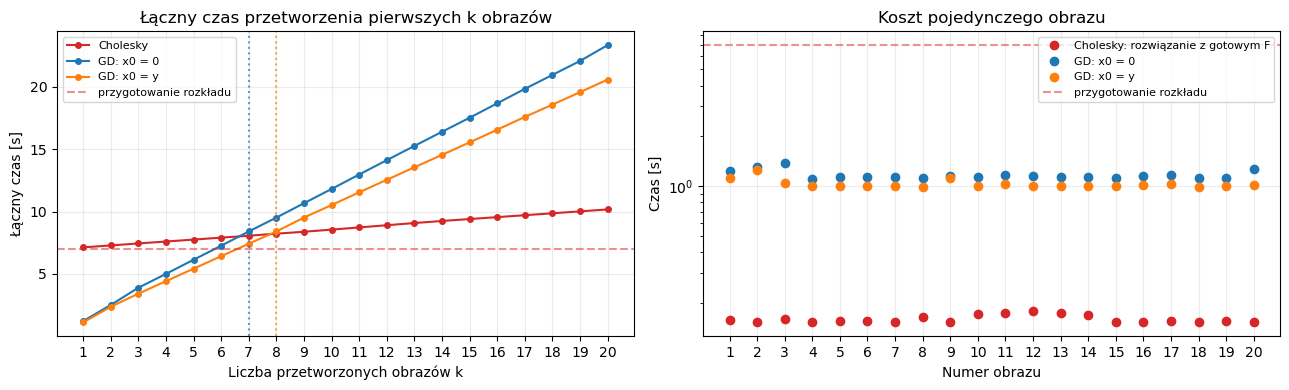

In [12]:
k = np.arange(1, n_images + 1)
cumulative = {"Cholesky": chol_setup + np.cumsum(chol["time"])}
for name in gd_runs:
    cumulative[name] = np.cumsum([run["time"] for run in gd_runs[name]])


def first_faster(chol_cum, gd_cum):
    # najmniejsze k, od którego Cholesky jest szybszy dla wszystkich kolejnych k ≤ 20
    faster = chol_cum < gd_cum
    for i in range(len(faster)):
        if faster[i:].all():
            return i + 1
    return None


print("wariant      | łączny czas (k=20) | śr. czas/obraz | kroki (min–max) | maks. ‖r‖ (GD) | maks. ‖y − Ax‖ | tolerancja osiągnięta")
print(f"{'Cholesky':12s} | {cumulative['Cholesky'][-1]:15.2f} s | {np.mean(chol['time']):12.3f} s | "
      f"{'—':>15s} | {'—':>14s} | {max(chol['residual']):14.2e} | —")
for name in gd_runs:
    runs = gd_runs[name]
    steps = [run["steps"] for run in runs]
    ok = sum(run["status"] == "OK" for run in runs)
    print(f"{name:12s} | {cumulative[name][-1]:15.2f} s | {np.mean([run['time'] for run in runs]):12.3f} s | "
          f"{min(steps):7d}–{max(steps):<7d} | {max(run['R'] for run in runs):14.2e} | "
          f"{max(run['residual'] for run in runs):14.2e} | {ok} / {n_images}")
print(f"(Cholesky: przygotowanie rozkładu {chol_setup:.2f} s wliczone w łączny czas)\n")

crossings = {}
for name in gd_runs:
    crossings[name] = first_faster(cumulative["Cholesky"], cumulative[name])
    estimate = chol_setup / (np.mean([run["time"] for run in gd_runs[name]]) - np.mean(chol["time"]))
    if crossings[name] is None:
        print(f"{name}: Cholesky nie staje się szybszy dla k ≤ {n_images} (z średnich kosztów: k > {estimate:.1f})")
    else:
        print(f"{name}: Cholesky szybszy od k = {crossings[name]} obrazów (z średnich kosztów: k > {estimate:.1f})")

plot = plt.subplots(1, 2, figsize=(13, 4))
fig = plot[0]
ax_cum, ax_each = plot[1]
colors = {"Cholesky": "C3", "GD: x0 = 0": "C0", "GD: x0 = y": "C1"}
for name in cumulative:
    ax_cum.plot(k, cumulative[name], "o-", markersize=4, color=colors[name], label=name)
for name in crossings:
    if crossings[name] is not None:
        ax_cum.axvline(crossings[name], color=colors[name], linestyle=":", alpha=0.7)
ax_cum.axhline(chol_setup, color="C3", linestyle="--", alpha=0.5, label="przygotowanie rozkładu")
ax_cum.set(xlabel="Liczba przetworzonych obrazów k", ylabel="Łączny czas [s]",
           title="Łączny czas przetworzenia pierwszych k obrazów", xticks=k)

ax_each.semilogy(k, chol["time"], "o", color="C3", label="Cholesky: rozwiązanie z gotowym F")
for name in gd_runs:
    ax_each.semilogy(k, [run["time"] for run in gd_runs[name]], "o", color=colors[name], label=name)
ax_each.axhline(chol_setup, color="C3", linestyle="--", alpha=0.5, label="przygotowanie rozkładu")
ax_each.set(xlabel="Numer obrazu", ylabel="Czas [s]", title="Koszt pojedynczego obrazu", xticks=k)
for ax in (ax_cum, ax_each):
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

Do przekrojów wybieramy dwa obrazy o najmniejszym $\max_i|c_i|$, czyli ze środkiem najbliżej środka obszaru (powłoka jest w większości wewnątrz siatki). Pokazujemy warstwę $p_2=\text{const}$ najbliższą $c_2$; dla danego obrazu wszystkie panele mają tę samą warstwę i wspólną skalę kolorów $[0,1]$.

obraz 12: c = (0.470, 0.136, 0.136), r₁ = 0.139, r₂ = 0.427, warstwa 36 (p₂ = 0.143)
    RMSE względem sygnału bez szumu: Dane y 0.3001, Cholesky 0.0766, GD: x₀ = 0 0.0766, GD: x₀ = y 0.0766
obraz 10: c = (-0.606, 0.598, -0.218), r₁ = 0.109, r₂ = 0.493, warstwa 25 (p₂ = -0.206)
    RMSE względem sygnału bez szumu: Dane y 0.3003, Cholesky 0.0778, GD: x₀ = 0 0.0778, GD: x₀ = y 0.0778


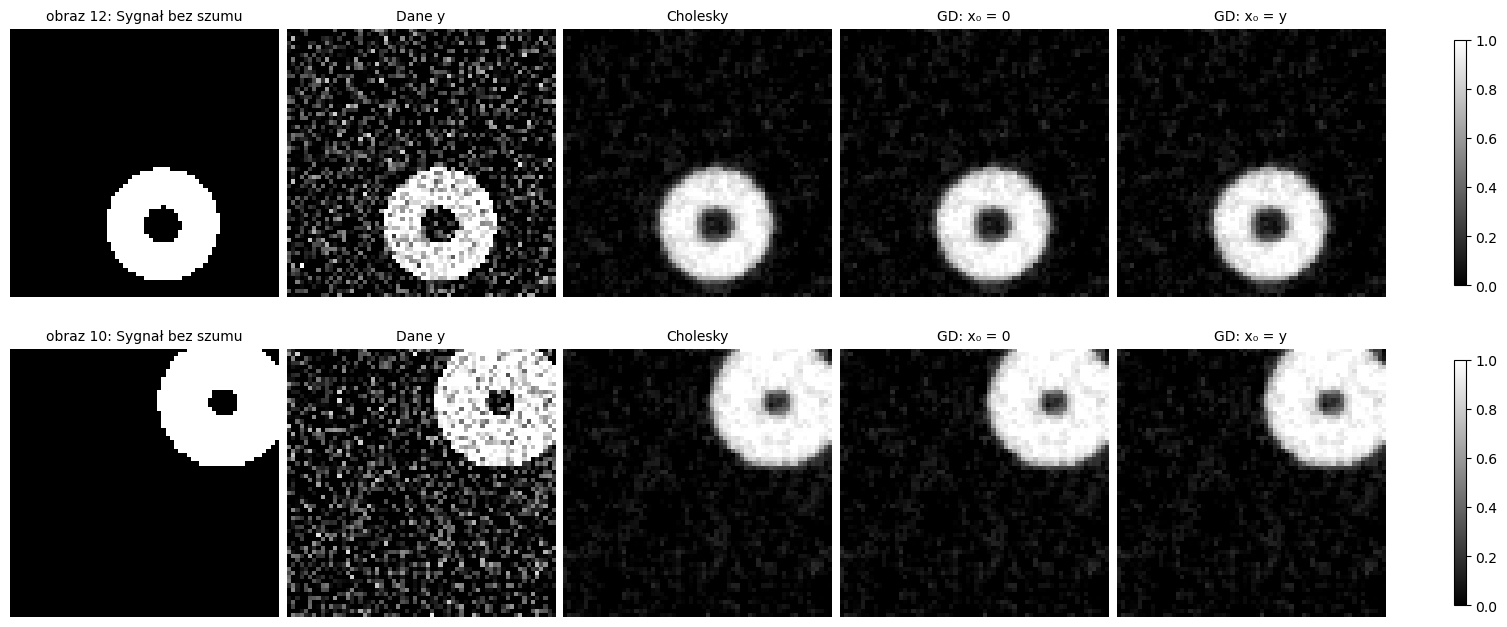

In [13]:
chosen = np.argsort([np.max(np.abs(image["c"])) for image in images])[:2]
titles = ["Sygnał bez szumu", "Dane y", "Cholesky", "GD: x₀ = 0", "GD: x₀ = y"]
plot = plt.subplots(2, 5, figsize=(15, 6.4), layout="constrained")
fig = plot[0]
axes = plot[1]
for row in range(2):
    j = chosen[row]
    image = images[j]
    layer = np.argmin(np.abs(q_grid - image["c"][2]))  # warstwa najbliższa środkowi powłoki
    volumes = [image["signal"], image["y"], chol["x"][j],
               gd_runs["GD: x0 = 0"][j]["x"], gd_runs["GD: x0 = y"][j]["x"]]
    for col in range(5):
        ax = axes[row, col]
        image_plot = ax.imshow(volumes[col].reshape(m, m, m)[:, :, layer],
                               cmap="gray", vmin=0., vmax=1.)
        ax.set_title(f"obraz {j}: {titles[col]}" if col == 0 else titles[col], fontsize=10)
        ax.set_axis_off()
    fig.colorbar(image_plot, ax=axes[row].tolist(), shrink=0.8)
    rmse = [np.sqrt(np.mean((v.ravel() - image["signal"].ravel())**2)) for v in volumes[1:]]
    print(f"obraz {j}: c = ({image['c'][0]:.3f}, {image['c'][1]:.3f}, {image['c'][2]:.3f}), "
          f"r₁ = {image['r1']:.3f}, r₂ = {image['r2']:.3f}, warstwa {layer} (p₂ = {q_grid[layer]:.3f})")
    print("    RMSE względem sygnału bez szumu: " +
          ", ".join(f"{titles[i + 1]} {rmse[i]:.4f}" for i in range(4)))
plt.show()

**Wnioski:**
- Wszystkie przebiegi GD osiągnęły tolerancję $10^{-12}$ (20/20 dla obu startów, status OK): $x_0=0$ - 215–223 iteracji, $x_0=y$ - 190–196 iteracji.
- Największa końcowa norma residuum: Cholesky $2{,}6\cdot10^{-13}$, GD z $x_0=0$ $9{,}93\cdot10^{-13}$, GD z $x_0=y$ $9{,}87\cdot10^{-13}$ (po przeliczeniu na nowo $\|y-Ax\|_2$ dla GD wychodzi ok. $1{,}2\cdot10^{-12}$).
- Cholesky staje się szybszy od GD z $x_0=0$ od 8 obrazów, a od GD z $x_0=y$ od 10 obrazów. Po 20 obrazach: 14,0 s wobec 28,7 s i 25,4 s.
- Rozkład Cholesky'ego jest drogi (ok. 10 s), ale zależy tylko od $A$, więc robimy go raz. Każdy kolejny obraz to już tylko dwa układy trójkątne z gotowym rozkładem - ok. 0,19 s. GD nie ma kosztu na start, ale każdy obraz kosztuje go ok. 1,3-1,4 s (ok. 200 iteracji). Dlatego przy kilku obrazach wygrywa GD, a przy wielu Cholesky.
- Start z $y$ jest o ok. 25 iteracji szybszy niż start z $0$: $y$ ma już prawie poprawną gładką część rozwiązania, którą GD poprawia najwolniej, a zostaje głównie szum, który GD wygasza szybko.
- Na przekrojach wyniki trzech metod wyglądają tak samo, bo rozwiązują ten sam układ. Wygładzenie usuwa większość szumu, ale rozmywa krawędzie powłoki.